# Robust optimization of the Texas TVEF battery hydrogen system

Two robust formulations on top of `tvef_model.py`:

1. **Robust over the scenario tree.** The leaves of the quarterly scenario tree form a finite uncertainty set.
   Instead of the expected cost, the first stage minimizes the cost of the *worst* scenario (epigraph
   formulation, `objective='minmax_cost'`), with the emission target imposed in every scenario. Because a pure
   min-max objective is indifferent among the non-worst scenarios, the lexicographic variant minimizes
   worst-case cost + 0.001 x expected cost in a single solve (`solve_lexicographic`, method 'weighted'): the worst
   case is traded against the expectation at 1000:1, which breaks the ties without a second large solve.
2. **Static budgeted robust counterpart per scope** (`H2System.add_robust_gwp_cap`). The emission coefficients may
   deviate upwards from their nominal values within intervals derived from the `PARAMS` ranges, and a budget
   $\Gamma_s$ per scope limits how many deviate at once (Bertsimas & Sim). The counterpart stays linear:

   \begin{equation}
   GWP^{nom} + \sum_{s} \Big( \Gamma_s z_s + \sum_{k \in K_s} q_{s,k} \Big) \le \epsilon, \qquad z_s + q_{s,k} \ge \hat{e}_{s,k}\, x_{s,k}, \qquad z_s, q_{s,k} \ge 0
   \end{equation}

   with $K_1$ the four reforming routes (deviation of the net CO2 coefficient at the worst corner of the yield and
   capture-rate ranges, $x$ = annual production), $K_2$ the days of the year (deviation of the hourly grid factor to the
   75th-percentile profile, $x$ = hourly grid consumption), and $K_3$ the single upstream-gas factor ($x$ = annual
   gas consumption). $\Gamma_s = 0$ is the nominal cap; the maximum budgets reproduce the deterministic model built at
   the worst corner (box), which is verified below.

Both sections use the 50 % reduction target of the epsilon-constraint sweep (cap = 723.66 kt CO2e), demand met or
exceeded (`demand_sign='geq'`), with ramp, minimum-load and smoothing constraints.

__author__ = "Marco De Sousa"
__copyright__ = "Copyright 2023, Multi-parametric Optimization & Control Lab"
__credits__ = ["Marco De Sousa", "Efstratios N. Pistikopoulos"]
__license__ = "MIT"
__version__ = "1.1.0"
__maintainer__ = "Marco De Sousa"
__email__ = "marcopdsousa@tamu.edu"
__status__ = "Production"

In [1]:
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tvef_model as tm
from tvef_model import ScenarioTree, H2SystemTree, H2System, make_inputs, PARAMS

data = tm.load_case_data()
nominal = make_inputs(data)
pd.set_option('display.width', 160)

GWP_BASE = 1447319785.076017          # cost-optimal GWP of the deterministic model (epsilon base)
TARGET_PCT = 50
CAP = GWP_BASE * (1 - TARGET_PCT / 100)
print(f'emission cap: {CAP:,.0f} kg CO2e')

emission cap: 723,659,893 kg CO2e


## 1. Robust over the scenario tree

Quarterly stages, each revealing a low-carbon or high-carbon quarter (25th / 75th percentile grid profile with
cheaper / dearer gas and power), 16 scenarios. Three first-stage designs are compared on the same tree:
expected cost (recourse problem), worst-case cost (min-max), and the lexicographic min-max.

In [2]:
branches = {
    'low-carbon':  (0.5, {'grid_ef_profile': '0.25', 'gas_price_level': 0.8, 'elec_price_level': 0.9}),
    'high-carbon': (0.5, {'grid_ef_profile': '0.75', 'gas_price_level': 1.2, 'elec_price_level': 1.1}),
}
STAGE_DAYS = [91, 91, 91, 92]
tree = ScenarioTree.product(STAGE_DAYS, branches)
print(tree)

tree_runs = {}

rp = H2SystemTree(data, tree, 'cost', 'geq')
rp.add_gwp_cap(CAP, mode='each')
rp.solve(tee=False)
rp.summary()
tree_runs['expected cost'] = dict(design=rp.design(), scenarios=rp.scenario_table(), objective=rp.m.ObjVal)
del rp

ScenarioTree(31 nodes, 16 scenarios, 365 days)
Set parameter Username


Academic license - for non-commercial use only - expires 2027-03-30


termination : optimal  (ScenarioTree(31 nodes, 16 scenarios, 365 days); node formulation)
objective   : 274,834,731.01  (cost)
exp. cost   : 274,834,731.01 USD  (capex 258,894, fopex 2,101, exp. opex 274,573,736)
exp. GWP    : 723,659,892.54 kg CO2e  (scope 1 270,590,749, scope 2 103,560,598, scope 3 349,508,546)
capacities  : ATR_CCS_R 22,702.7, ATR_CCS_R_OC 0.0, AWE 0.0, D1 0.0, D2 0.0, D3 0.0, D4 0.0, Grid 86.1, LiI 25.0, LiI_discharge 25.0, PEM 0.0, PV 600.0, SMR 4,740.8, SMRCCS 0.0, WF 650.0
storage     : LiI_Power_stored 200.00


In [3]:
mm = H2SystemTree(data, tree, 'minmax_cost', 'geq')
mm.add_gwp_cap(CAP, mode='each')
mm.solve(tee=False)
mm.summary()
tree_runs['min-max cost'] = dict(design=mm.design(), scenarios=mm.scenario_table(), objective=mm.m.ObjVal)
del mm

termination : optimal  (ScenarioTree(31 nodes, 16 scenarios, 365 days); node formulation)
objective   : 314,742,774.68  (minmax_cost)
exp. cost   : 313,291,393.44 USD  (capex 258,989, fopex 2,119, exp. opex 313,030,285)
exp. GWP    : 722,955,399.21 kg CO2e  (scope 1 269,889,867, scope 2 80,591,290, scope 3 372,474,242)
capacities  : ATR_CCS_R 23,110.3, ATR_CCS_R_OC 0.0, AWE 0.0, D1 750.0, D2 966.9, D3 431.6, D4 219.8, Grid 86.2, LiI 25.0, LiI_discharge 25.0, PEM 0.0, PV 600.0, SMR 4,503.0, SMRCCS 0.0, WF 650.0
storage     : LiI_Power_stored 200.00


In [4]:
lx = H2SystemTree(data, tree, 'cost', 'geq')
lx.add_gwp_cap(CAP, mode='each')
lx.solve_lexicographic(primary='minmax_cost', secondary='cost', method='weighted', weight=1e-3)
print(f'worst-case cost of the lexicographic design: {lx.primary_value:,.2f} USD')
lx.summary()
tree_runs['lexicographic'] = dict(design=lx.design(), scenarios=lx.scenario_table(), objective=lx.m.ObjVal)
del lx

worst-case cost of the lexicographic design: 314,742,775.38 USD


termination : optimal  (ScenarioTree(31 nodes, 16 scenarios, 365 days); node formulation)
objective   : 315,017,619.61  (minmax_cost + 0.001 * cost)
exp. cost   : 274,844,231.92 USD  (capex 258,989, fopex 2,119, exp. opex 274,583,124)
exp. GWP    : 723,659,891.83 kg CO2e  (scope 1 270,641,337, scope 2 103,508,292, scope 3 349,510,263)
capacities  : ATR_CCS_R 23,110.0, ATR_CCS_R_OC 0.0, AWE 0.1, D1 0.0, D2 0.0, D3 0.0, D4 0.0, Grid 87.3, LiI 25.0, LiI_discharge 25.0, PEM 0.0, PV 600.0, SMR 4,503.3, SMRCCS 0.1, WF 650.0
storage     : LiI_Power_stored 200.00


In [5]:
rows = []
for name, r in tree_runs.items():
    sc = r['scenarios']
    d = r['design']
    rows.append({'design': name, 'expected cost [USD]': float((sc['prob'] * sc['cost']).sum()),
                 'worst scenario [USD]': sc['cost'].max(), 'best scenario [USD]': sc['cost'].min(),
                 'cost std [USD]': float(np.sqrt((sc['prob'] * (sc['cost'] - (sc['prob'] * sc['cost']).sum()) ** 2).sum())),
                 'SMR [kg/hr]': d['Cap_P']['SMR'], 'ATR_CCS_R [kg/hr]': d['Cap_P']['ATR_CCS_R'],
                 'PEM [kg/hr]': d['Cap_P']['PEM'], 'battery [MWh]': d['Cap_S'].iloc[0]})
tree_cmp = pd.DataFrame(rows).set_index('design')
tree_cmp.round(0)

,expected cost [USD],worst scenario [USD],best scenario [USD],cost std [USD],SMR [kg/hr],ATR_CCS_R [kg/hr],PEM [kg/hr],battery [MWh]
design,,,,,,,,
expected cost,274834731.0,314765189.0,234931829.0,20343631.0,4741.0,22703.0,0.0,200.0
min-max cost,313291393.0,314742775.0,307272935.0,1936790.0,4503.0,23110.0,0.0,200.0
lexicographic,274844232.0,314742776.0,234951645.0,20335934.0,4503.0,23110.0,0.0,200.0


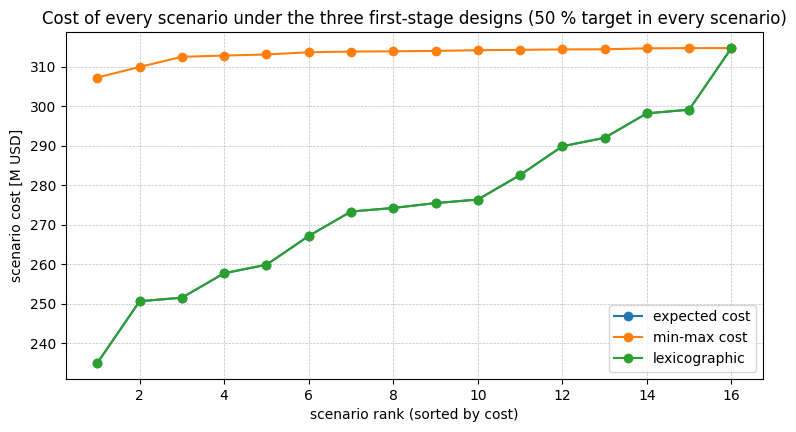

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, r in tree_runs.items():
    costs = np.sort(r['scenarios']['cost'].to_numpy())
    ax.plot(np.arange(1, len(costs) + 1), costs / 1e6, marker='o', label=name)
ax.set_xlabel('scenario rank (sorted by cost)')
ax.set_ylabel('scenario cost [M USD]')
ax.set_title('Cost of every scenario under the three first-stage designs (50 % target in every scenario)')
ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
ax.legend()
plt.show()

## 2. Static budgeted robust counterpart per scope

Deviations are taken from the `PARAMS` ranges (see `H2System.robust_deviations`). The nominal grid profile is the
mean and the band is the 75th-percentile profile, so $\Gamma_2 = 365$ puts every day at the 75th percentile, which is
exactly the percentile scenario of the paper.

In [7]:
probe = H2System(nominal, 'cost', 'geq')
dev = probe.robust_deviations(band='0.75')
dev_table = pd.DataFrame({'nominal net CO2 [kg/kg H2]': dev['e1_nominal'], 'worst corner [kg/kg H2]': dev['e1_worst'],
                          'deviation [kg/kg H2]': dev['scope1']})
print(f"scope 2: mean hourly deviation {dev['scope2'].mean():.1f} kg CO2e/MWh (max {dev['scope2'].max():.1f}), "
      f"band = {dev['band']} quantile profile")
print(f"scope 3: upstream gas deviation {dev['scope3']:.3f} kg CO2e/kg NG (nominal {nominal['resources'][tm.NG]['gwp']:.3f})")
del probe
dev_table.round(3)

scope 2: mean hourly deviation 75.1 kg CO2e/MWh (max 139.2), band = 0.75 quantile profile
scope 3: upstream gas deviation 1.539 kg CO2e/kg NG (nominal 0.961)


,nominal net CO2 [kg/kg H2],worst corner [kg/kg H2],deviation [kg/kg H2]
SMR,9.371,10.300,0.929
SMRCCS,-8.903,-6.849,2.053
ATR_CCS_R,0.450,3.044,2.594
ATR_CCS_R_OC,0.664,3.418,2.754


In [8]:
BUDGETS = {1: [0, 1, 2, 3, 4], 2: [0, 30, 90, 180, 365], 3: [0, 0.25, 0.5, 0.75, 1.0]}
GAMMA_MAX = {1: 4, 2: 365, 3: 1.0}

sweep = []
t0 = time.time()
for s, grid in BUDGETS.items():
    for g in grid:
        mdl = H2System(nominal, 'cost', 'geq')
        mdl.add_robust_gwp_cap(CAP, gamma={s: g}, band='0.75')
        mdl.solve(tee=False)
        rv = mdl.robust_values() if mdl.status == 'optimal' else {}
        d = mdl.frames() if mdl.status == 'optimal' else None
        sweep.append({'scope': s, 'gamma': g, 'gamma_rel': g / GAMMA_MAX[s], 'status': mdl.status,
                      'cost': mdl.m.ObjVal if mdl.status == 'optimal' else np.nan,
                      'nominal_gwp': rv.get('nominal_gwp', np.nan), 'worst_case_gwp': rv.get('worst_case_gwp', np.nan),
                      'SMR': d['Cap_P']['SMR'] if d else np.nan, 'ATR_CCS_R': d['Cap_P']['ATR_CCS_R'] if d else np.nan,
                      'ATR_CCS_R_OC': d['Cap_P']['ATR_CCS_R_OC'] if d else np.nan, 'SMRCCS': d['Cap_P']['SMRCCS'] if d else np.nan,
                      'PEM': d['Cap_P']['PEM'] if d else np.nan, 'AWE': d['Cap_P']['AWE'] if d else np.nan,
                      'battery_MWh': d['Cap_S'].iloc[0] if d else np.nan,
                      'penalty_H2_kg': float(sum(d['P'].loc[k].sum() for k in ['D1', 'D2', 'D3', 'D4'])) if d else np.nan})
        del mdl
print(f'{len(sweep)} robust solves in {time.time() - t0:.0f} s')
sweep_df = pd.DataFrame(sweep)
base_cost = sweep_df.loc[(sweep_df.scope == 1) & (sweep_df.gamma == 0), 'cost'].iloc[0]
sweep_df['price_of_robustness_pct'] = 100 * (sweep_df['cost'] / base_cost - 1)
sweep_df.round(1)

15 robust solves in 1407 s


,scope,gamma,gamma_rel,status,cost,nominal_gwp,worst_case_gwp,SMR,ATR_CCS_R,ATR_CCS_R_OC,SMRCCS,PEM,AWE,battery_MWh,penalty_H2_kg,price_of_robustness_pct
0,1,0.0,0.0,optimal,274908729.8,723659892.5,723659892.5,4920.8,22551.5,0.0,0.0,0.0,0.0,200.0,0.0,0.0
1,1,1.0,0.2,optimal,280060424.3,583583046.3,723659892.5,1211.0,13540.0,12893.6,0.0,0.0,0.0,200.0,0.0,1.9
2,1,2.0,0.5,optimal,301625965.4,436067596.3,723659892.5,0.0,27546.8,0.0,0.0,0.0,0.0,100.0,0.0,9.7
3,1,3.0,0.8,optimal,301625967.1,436067590.9,723659892.5,0.0,27546.8,0.0,0.0,0.0,0.0,100.0,0.0,9.7
4,1,4.0,1.0,optimal,301625967.8,436067588.5,723659892.5,0.0,27546.8,0.0,0.0,0.0,0.0,100.0,0.0,9.7
5,2,0.0,0.0,optimal,274908729.8,723659892.5,723659892.5,4920.8,22551.5,0.0,0.0,0.0,0.0,200.0,0.0,0.0
6,2,30.0,0.1,optimal,274962119.9,721719651.0,723659892.5,4866.7,22605.5,0.0,0.0,0.0,0.0,200.0,0.0,0.0
7,2,90.0,0.2,optimal,275053825.3,718323799.2,723659892.5,4793.3,22721.2,0.0,0.0,0.0,0.0,200.0,0.0,0.1
8,2,180.0,0.5,optimal,275175866.5,713802735.2,723659892.5,4680.1,22844.7,0.0,0.0,0.0,0.0,200.0,0.0,0.1
9,2,365.0,1.0,optimal,275382242.2,706068218.6,723659892.5,4515.1,23086.4,0.0,0.0,0.0,0.0,200.0,0.0,0.2


### Verification: full box = deterministic model at the worst corner

In [9]:
box = H2System(nominal, 'cost', 'geq')
box.add_robust_gwp_cap(CAP, gamma={1: 4, 2: 365, 3: 1.0}, band='0.75')
box.solve(tee=False)
corner_inputs = make_inputs(data, {'reformer_co2_yield': PARAMS.loc['reformer_co2_yield', 'high'],
                                   'capture_rate_factor': PARAMS.loc['capture_rate_factor', 'low'],
                                   'ng_upstream_ef': PARAMS.loc['ng_upstream_ef', 'high'],
                                   'grid_ef_profile': '0.75'})
corner = H2System(corner_inputs, 'cost', 'geq')
corner.add_gwp_cap(CAP)
corner.solve(tee=False)
print(f'box robust counterpart : {box.m.ObjVal:,.2f} USD  (worst-case GWP {box.robust_values()["worst_case_gwp"]:,.0f}, nominal GWP {box.robust_values()["nominal_gwp"]:,.0f})')
print(f'deterministic corner   : {corner.m.ObjVal:,.2f} USD  (GWP {float(corner.gwp_total.getValue()):,.0f})')
print(f'difference             : {box.m.ObjVal - corner.m.ObjVal:.3e} USD')
box.summary()
del box, corner

box robust counterpart : 968,103,462.95 USD  (worst-case GWP 723,659,893, nominal GWP 231,059,967)
deterministic corner   : 968,103,462.95 USD  (GWP 723,659,893)
difference             : -8.860e-04 USD


termination : optimal
objective   : 968,103,462.95  (cost)
total cost  : 968,103,462.95 USD  (capex 40,229, fopex 5,718, vopex 119,486,658, purchase 848,570,858)
total GWP   : 231,059,966.75 kg CO2e  (scope 1 29,402,932, scope 2 29,491, scope 3 201,627,544)
capacities  : ATR_CCS_R 17,271.6, ATR_CCS_R_OC 0.0, AWE 0.0, D1 750.0, D2 2,250.0, Grid 14.0, LiI 25.0, LiI_discharge 25.0, PEM 6,194.8, PV 600.0, SMR 0.0, SMRCCS 0.0, WF 650.0
storage     : LiI_Power_stored 19.91


### Price of robustness per scope

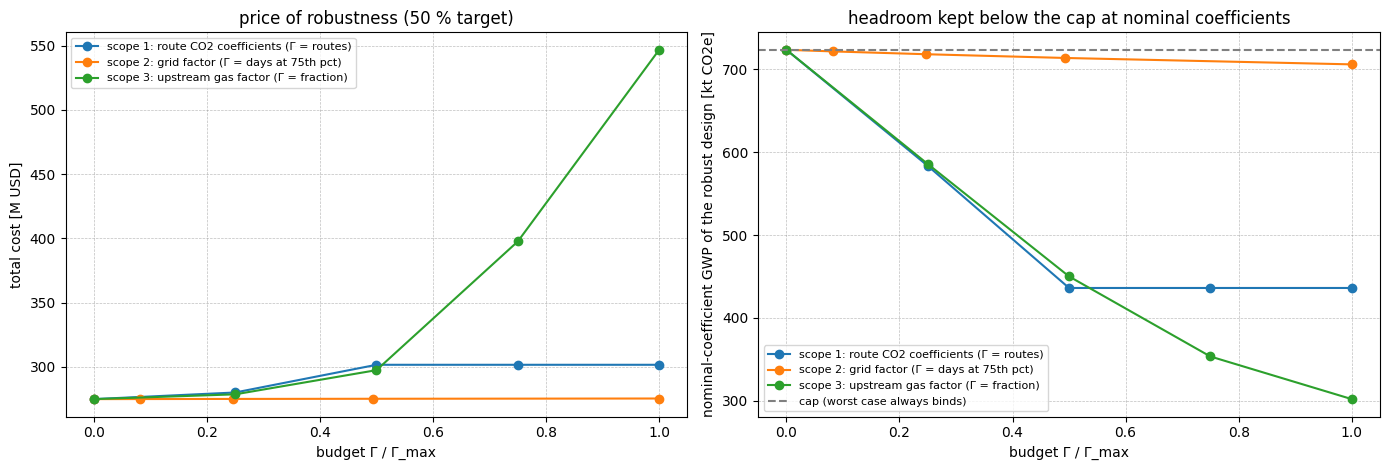

In [10]:
labels = {1: 'scope 1: route CO2 coefficients (Γ = routes)', 2: 'scope 2: grid factor (Γ = days at 75th pct)',
          3: 'scope 3: upstream gas factor (Γ = fraction)'}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for s, grp in sweep_df.groupby('scope'):
    axes[0].plot(grp['gamma_rel'], grp['cost'] / 1e6, marker='o', label=labels[s])
    axes[1].plot(grp['gamma_rel'], grp['nominal_gwp'] / 1e6, marker='o', label=labels[s])
axes[0].set_xlabel('budget Γ / Γ_max')
axes[0].set_ylabel('total cost [M USD]')
axes[0].set_title('price of robustness (50 % target)')
axes[1].axhline(CAP / 1e6, color='gray', linestyle='--', label='cap (worst case always binds)')
axes[1].set_xlabel('budget Γ / Γ_max')
axes[1].set_ylabel('nominal-coefficient GWP of the robust design [kt CO2e]')
axes[1].set_title('headroom kept below the cap at nominal coefficients')
for ax in axes:
    ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

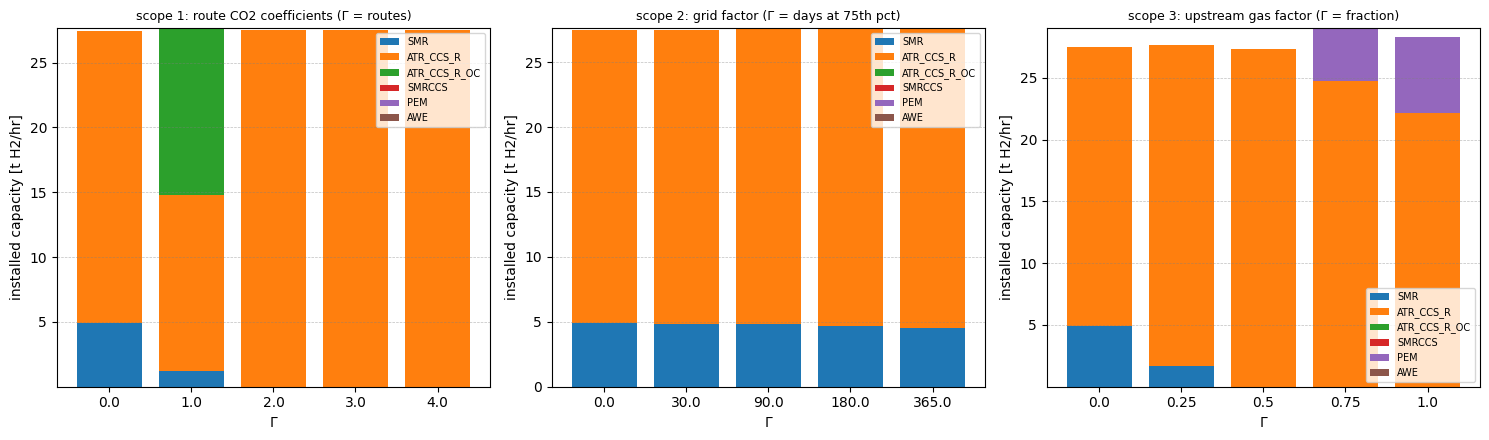

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
techs = ['SMR', 'ATR_CCS_R', 'ATR_CCS_R_OC', 'SMRCCS', 'PEM', 'AWE']
for ax, (s, grp) in zip(axes, sweep_df.groupby('scope')):
    bottom = np.zeros(len(grp))
    for tech in techs:
        vals = grp[tech].to_numpy() / 1e3
        if np.nanmax(vals) > 0:
            ax.bar(grp['gamma'].astype(str), vals, bottom=bottom, label=tech)
            bottom += np.nan_to_num(vals)
    ax.set_title(labels[s], fontsize=9)
    ax.set_xlabel('Γ')
    ax.set_ylabel('installed capacity [t H2/hr]')
    ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5, axis='y')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [12]:
with open('Gurobipy_robust_results.pkl', 'wb') as f:
    pickle.dump({'tree_runs': tree_runs, 'tree_comparison': tree_cmp, 'budget_sweep': sweep_df, 'deviations': dev,
                 'cap': CAP, 'branches': branches, 'stage_days': STAGE_DAYS}, f)
print('saved Gurobipy_robust_results.pkl')

saved Gurobipy_robust_results.pkl


## Reading the results

- The tree comparison shows what worst-case protection costs in expectation and how much it changes the design.
- In the budget sweep the worst-case GWP always equals the cap (the robust constraint binds), so the second panel
  shows how much *nominal* headroom each robust design keeps. The cost curve per scope is the scope-specific price of
  robustness; a flat curve means the uncertainty of that scope is cheap to insure against, a steep one means it forces
  a structural change (visible in the capacity bars).
- $\Gamma_3$ is a single parameter, so its curve is simply the cost of tightening the cap by the realized fraction of
  the upstream deviation; $\Gamma_1$ counts routes, so the curve saturates once the routes actually used are at their
  worst coefficient.